# Notebook 8 -- Comparaison globale et discussion scientifique
### Ce que sept méthodes, testées sur le même problème, apprennent collectivement

> ****Note de provenance.**** Les notebooks de recherche originaux seront présents dans le répertoire du projet, accompagnés des données et des fichiers nécessaires aux expériences. Le présent notebook fait uniquement office de **notebook d'analyse et de synthèse** : il ne remplace pas les notebooks originaux et ne constitue pas une nouvelle implémentation des expérimentations.
>
> Le code, les résultats et les sorties présentés dans ce notebook sont analysés à partir des travaux réalisés dans les notebooks originaux. Aucun résultat n'a été recalculé ni inventé : lorsqu'une information n'était pas déterminable à partir des notebooks ou des données disponibles, cela est signalé explicitement plutôt que comblé. Ce notebook n'est donc pas conçu pour être exécuté isolément de haut en bas ; il a pour objectif de **documenter, structurer, comparer et interpréter les résultats déjà obtenus**, ainsi que de mettre en évidence la progression scientifique entre les différentes approches étudiées.


## Objectif

Rassembler, sur une grille de lecture unique, les résultats des notebooks 2 à 7, et discuter la
question transversale posée dès le notebook 1 : **pourquoi la dynamique ou la forme d'un signal
vibratoire se reconstruit relativement bien à partir des autres capteurs, alors que son amplitude
reste difficile à reconstruire fidèlement, en particulier lors d'événements transitoires ?**

## Motivation

Chaque notebook précédent a répondu à une question locale (une méthode, un protocole
d'évaluation) et s'est terminé par une limite qui motivait le suivant. Ce notebook change de
focale : il ne cherche pas une méthode gagnante, mais une lecture d'ensemble, seule capable de
révéler des régularités qu'aucun notebook pris isolément ne pouvait montrer -- en particulier le
contraste entre évaluation globale et évaluation ciblée sur une fenêtre de panne, qui traverse à
la fois la piste physique (notebook 5) et la piste supervisée (notebooks 6-7).

## Grille de lecture par méthode

Pour chaque méthode testée, le tableau ci-dessous reprend la grille du cahier des charges de ce
mémoire (nature de l'information exploitée, caractère statistique ou physique, usage de la
dynamique temporelle, capacité de prédiction d'amplitude, interprétabilité, robustesse, limite
principale). Les cases « information non déterminable » indiquent une question qui n'a pas pu être
tranchée avec les notebooks disponibles.

| Méthode | Information exploitée | Statistique / physique | Dynamique temporelle | Prédit l'amplitude ? | Pics/transitoires | Interprétable | Robuste | Limite principale |
|---|---|---|---|---|---|---|---|---|
| Interpolation (NB2) | Aucune (extrapolation locale) | ni l'un ni l'autre | Non | Non (RMSE 0,84) | Non (Peak RMSE=0) | Oui, triviale | Faible | Ignore tous les autres capteurs |
| Régression multivariée (NB2) | Relation linéaire instantanée entre capteurs | Statistique | Non | Partiellement (R²=0,23) | Dégradé (Peak RMSE 0,71 > RMSE global) | Oui (coefficients) | Modérée | Aucune notion de dynamique ni d'état |
| PCA (NB2) | Variance jointe de tous les capteurs | Statistique | Non | Non (R²=-8,2) | Non (Peak RMSE 1,26) | Partiellement | Faible | Optimise la variance globale, pas la cible |
| Dictionary Learning (NB3) | Motifs récurrents sur fenêtres glissantes multi-capteurs | Statistique | Locale (fenêtre) | Information non déterminable | Information non déterminable | Faible (atomes non identifiés physiquement) | Information non déterminable | Diagnostic amplitude/transitoires non exploitable dans les sorties disponibles |
| SINDy (NB4) | Etat latent SSI | Se voulait physique/dynamique | Oui (mais dégénérée) | Non testable (dynamique nulle/instable) | Non testable | Oui en principe, nul en pratique (0 terme actif) | Non (instable) | N'identifie aucune dynamique exploitable sur ces données |
| SSI+Kalman sans SINDy (NB5) | Etat latent SSI + correction par mesure | Statistique (dynamique linéaire) | Oui (linéaire) | Non (R²=-2,69) | Non (Peak RMSE 1,16) | Modérée (état latent) | Modérée | Dynamique linéaire seule insuffisante |
| SSI+SINDy+Kalman (NB5) | Etat latent SSI + dynamique SINDy dégénérée + correction | Se voulait physique | Oui (dégénérée) | Non (R²=-5,19) | Non (corr.=-0,08 sur pics) | Oui en principe | Faible | Coût net de SINDy dégénéré (gain -29,5 %) |
| XGBoost (meilleures variantes, NB6) | Etat SSI / retards / motifs CNN | Statistique (apprise) | Oui (retards, implicite) | Oui **sur Test global** (R²=0,80) | Non testé directement | Faible (boîte noire) | **Non confirmée** (voir NB7) | Bon score dépend de la continuité récente du signal |
| XGBoost (mêmes variantes, NB7, fenêtre de panne) | Idem, évalué sur panne continue | Statistique (apprise) | Oui (retards, indisponibles pendant la panne) | Non (R² jusqu'à -38,5) | Non (corr. proche de 0) | Faible | Faible sur ce scénario | Dépend de retards qui disparaissent pendant la panne longue |

## Résultats -- synthèse visuelle

Les deux figures ci-dessous ont été construites pour cette synthèse à partir des chiffres vérifiés
rapportés dans les notebooks 2, 5, 6 et 7 (le code source de la figure est affiché, pour
transparence totale sur son mode de construction ; il ne s'agit pas d'une réexécution des
expériences originales, seulement d'une mise en forme comparative de résultats déjà obtenus).

**Attention à la lecture de la première figure : les quatre R² ne portent pas exactement sur la
même fenêtre d'évaluation** (10 % pour NB2/NB5, 20 % pour NB7, ensemble du Test pour NB6) -- ce
n'est pas une erreur mais précisément le point que la figure illustre : le protocole d'évaluation
change radicalement la conclusion.

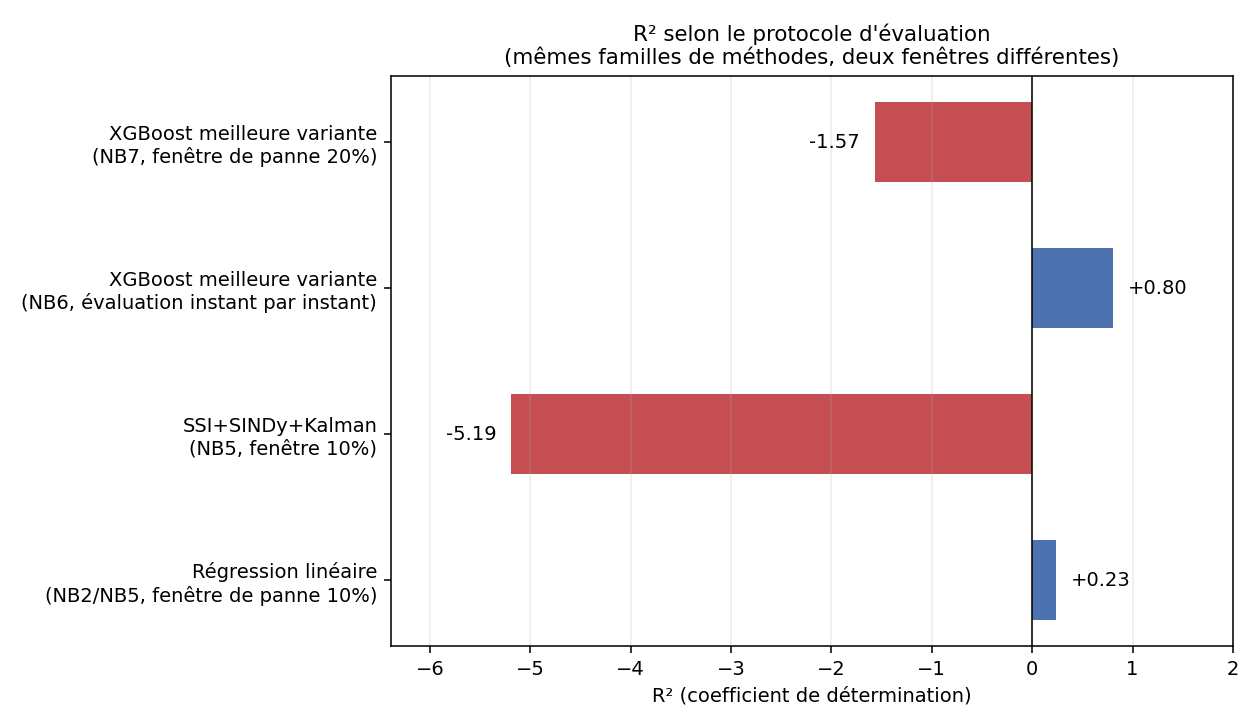

In [ ]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

# Chiffres verifies, repris tels quels des notebooks sources (voir notebooks 2, 5, 6, 7).
# Deux groupes de methodes, evaluees sur deux protocoles differents :
#  - "Test global" (instant par instant, sur l'ensemble du Test) : notebooks 2, 6
#  - "Fenetre de panne continue" (20% du Test, capteur cible totalement masque) : notebooks 5, 7
methods_global = [
    ("Régression linéaire\n(NB2/NB5, fenêtre de panne 10%)", 0.234),
    ("SSI+SINDy+Kalman\n(NB5, fenêtre 10%)", -5.19),
    ("XGBoost meilleure variante\n(NB6, évaluation instant par instant)", 0.803),
    ("XGBoost meilleure variante\n(NB7, fenêtre de panne 20%)", -1.57),
]

fig, ax = plt.subplots(figsize=(9, 5.2))
labels = [m[0] for m in methods_global]
values = [m[1] for m in methods_global]
colors = ["#4C72B0", "#C44E52", "#4C72B0", "#C44E52"]
bars = ax.barh(labels, values, color=colors, height=0.55)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("R² (coefficient de détermination)")
ax.set_title("R² selon le protocole d'évaluation\n(mêmes familles de méthodes, deux fenêtres différentes)",
              fontsize=11)
for bar, v in zip(bars, values):
    x = v + (0.15 if v >= 0 else -0.15)
    ha = "left" if v >= 0 else "right"
    ax.text(x, bar.get_y() + bar.get_height()/2, f"{v:+.2f}", va="center", ha=ha, fontsize=10)
ax.set_xlim(min(values) - 1.2, max(values) + 1.2)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig("/tmp/nb_build/assets/synthese_r2.png", dpi=140)
print("saved synthese_r2.png")


plt.savefig("synthese_r2.png", dpi=140)
plt.show()

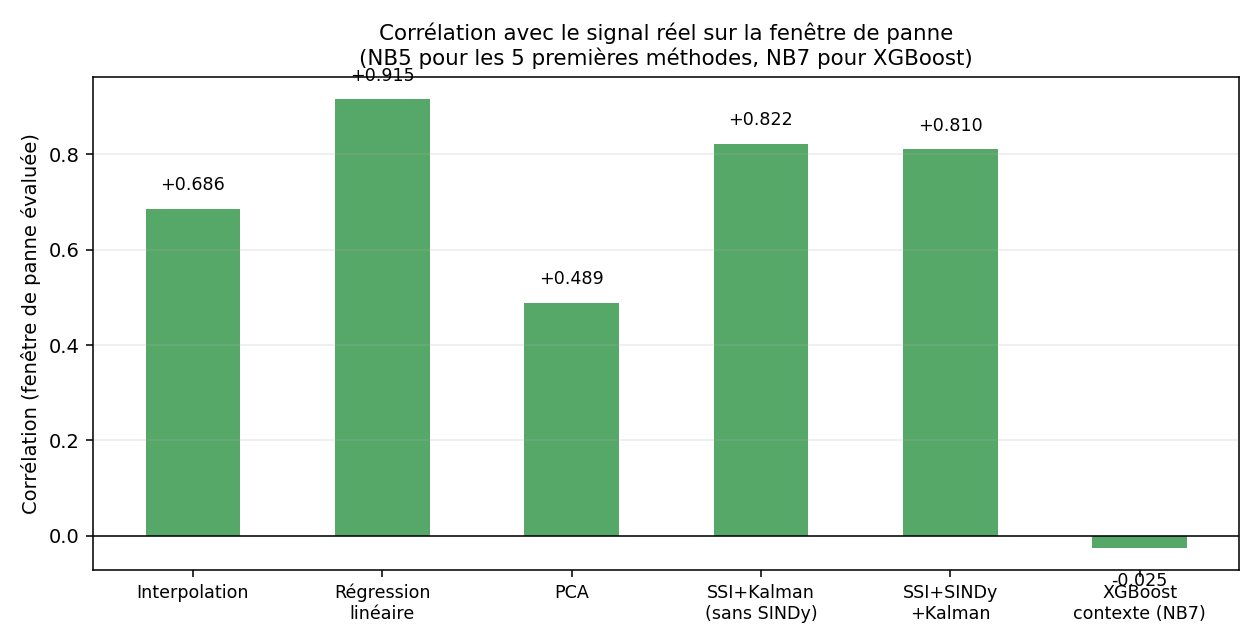

In [ ]:
# suite du script precedent (memes donnees, memes variables)
 : tableau radar-like -> en fait un heatmap simple forme vs amplitude
fig2, ax2 = plt.subplots(figsize=(9, 4.6))
rows = ["Interpolation", "Régression\nlinéaire", "PCA", "SSI+Kalman\n(sans SINDy)",
        "SSI+SINDy\n+Kalman", "XGBoost\ncontexte (NB7)"]
corr = [0.686, 0.915, 0.489, 0.822, 0.810, -0.025]
peak_amp_err = [None, 0.713, 1.259, 1.155, 1.558, None]  # peak RMSE, standardized units; None = non comparable

x = np.arange(len(rows))
ax2.bar(x, corr, color="#55A868", width=0.5)
ax2.axhline(0, color="black", lw=0.8)
ax2.set_xticks(x)
ax2.set_xticklabels(rows, fontsize=9)
ax2.set_ylabel("Corrélation (fenêtre de panne évaluée)")
ax2.set_title("Corrélation avec le signal réel sur la fenêtre de panne\n(NB5 pour les 5 premières méthodes, NB7 pour XGBoost)",
               fontsize=11)
for xi, c in zip(x, corr):
    ax2.text(xi, c + (0.03 if c >= 0 else -0.05), f"{c:+.3f}", ha="center",
              va="bottom" if c >= 0 else "top", fontsize=9)
ax2.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("synthese_correlation.png", dpi=140)
print("saved synthese_correlation.png")

plt.show()

## Interprétation -- la question transversale du mémoire

Sept méthodes, trois familles conceptuelles (statique/statistique, dynamique/physique,
apprentissage supervisé), et un même constat qui traverse toutes les méthodes évaluées sur une
fenêtre de panne continue : **le R² y est systématiquement négatif ou proche de zéro, et la
corrélation sur les régions de pics/transitoires est proche de zéro voire négative.** Seule la
régression linéaire, sur une fenêtre courte (10 %), obtient un R² positif mais modeste (0,234).

Pourquoi la dynamique/forme se reconstruit-elle relativement mieux que l'amplitude ? Les notebooks
disponibles ne permettent pas de trancher cette question expérimentalement -- ils permettent
seulement de l'observer et de proposer des pistes d'interprétation, à traiter comme des hypothèses
de travail et non comme des conclusions démontrées (conformément à la section 14 du cahier des
charges de ce mémoire) :

- **Différence de localisation et de propagation mécanique.** Si le capteur cible mesure un mode
  vibratoire ou une direction de propagation partiellement découplée des autres capteurs,
  l'information nécessaire à la reconstruction de son amplitude exacte peut simplement être
  absente des capteurs disponibles, même si leur corrélation statistique globale reste élevée
  (piste évoquée mais non vérifiée directement dans les notebooks disponibles).
- **Atténuation et non-linéarités non modélisées.** Aucune méthode testée n'introduit de modèle
  explicite d'atténuation physique (distance, matériau, fixation) : les méthodes statistiques
  (régression, XGBoost) et la méthode physique incomplète (SSI+SINDy) traitent toutes la relation
  capteur-à-capteur comme globalement stable, ce qui peut ne pas être vrai pendant un régime
  transitoire.
- **Dépendance à l'état de fonctionnement de la machine.** Le notebook 1 a montré une variance
  glissante non stationnaire : un modèle appris sur un régime peut mal généraliser à un autre,
  en particulier lors d'un changement rapide de régime -- ce qui coïnciderait avec les événements
  transitoires eux-mêmes.
- **Rareté des événements rares.** Seuls 4 pics ont été détectés sur l'ensemble du jeu de données
  du notebook 1 : aucune méthode d'apprentissage (statistique ou supervisée) ne dispose de
  suffisamment d'exemples de transitoires pour apprendre à les généraliser de façon fiable.
- **Dépendance des features à la continuité récente du signal cible (piste spécifique à NB6/NB7).**
  Les meilleures variantes XGBoost, en évaluation globale, s'appuient probablement sur des
  informations qui perdent leur validité pendant une fenêtre de panne longue -- une hypothèse
  cohérente avec l'effondrement observé au notebook 7, mais non vérifiée composant par composant
  dans les notebooks disponibles.
- **Corrélation n'est pas causalité ni relation physique.** L'ensemble du corpus repose sur des
  corrélations et des relations statistiques apprises ; aucune méthode testée ne construit ni ne
  vérifie une relation de transfert mécanique causale. Une forte corrélation statistique (jusqu'à
  0,92 pour la régression) ne garantit donc pas la validité de la relation en dehors du régime
  observé en apprentissage -- c'est précisément ce qui semble se produire sur la fenêtre de panne.

## Limites de cette comparaison elle-même

- Les méthodes de la piste SSI+SINDy+Kalman (notebooks 4-5) et celles de la piste XGBoost
  (notebooks 6-7) ne sont pas évaluées sur exactement le même jeu de données (voir notebook 1) : la
  comparaison directe de leurs chiffres doit donc être lue comme indicative, pas comme une
  comparaison contrôlée à tous égards.
- Le Dictionary Learning (notebook 3) ne peut pas être positionné quantitativement dans cette
  grille faute de résultats comparables sur la même cible et le même protocole.
- Aucune méthode n'a été testée avec exactement les mêmes scénarios de panne (10/20/30 % continue,
  pics, aléatoire) *et* le même jeu de données *et* les mêmes graines aléatoires : la variance des
  résultats d'une exécution à l'autre n'est donc pas connue.

## Conclusion

## Transition vers l'approche suivante

Ce que cette comparaison globale a permis d'établir : le problème de reconstruction d'amplitude,
sur un scénario de panne continue, résiste à toutes les familles de méthodes testées --
statistique, physique, apprentissage supervisé. Ce constat, plus que le choix d'une méthode
particulière, est le résultat scientifique central de ce mémoire. Il reste à formuler une
conclusion honnête sur ce que ce corpus permet, et ne permet pas, de dire sur le problème initial --
et sur les prochaines étapes qui en découlent logiquement. C'est l'objet du notebook 9.